In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shixft+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__notebook__.ipynb
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__output__.json
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__results__.html
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/custom.css
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/test.csv
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/train.csv
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__results___files/__results___12_0.png
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__results___files/__results___14_0.png
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__results___files/__results___18_0.png
/kaggle/input/notebooks/chocozzz/01-goodbooks-10k-data-exploratory-analysis/__results___files/__results___20_0.png
/k

# Input the dataset

In [8]:
import kagglehub
from fastai.collab import *
from fastai.tabular.all import *
import pandas as pd

path = Path(kagglehub.dataset_download("zygmunt/goodbooks-10k"))

path.ls()
# Check the files: look for ratings.csv and books.csv

[Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/book_tags.csv'), Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/books.csv'), Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/ratings.csv'), Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/sample_book.xml'), Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/tags.csv'), Path('/kaggle/input/datasets/zygmunt/goodbooks-10k/to_read.csv')]

In [9]:
ratings = pd.read_csv(path/'ratings.csv')
ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [11]:
ratings.shape

(981756, 3)

In [13]:
books = pd.read_csv(path/'books.csv')
books[['book_id', 'title', 'authors']].head(10)

,book_id,title,authors
0,2767052,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
1,3,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré"
2,41865,"Twilight (Twilight, #1)",Stephenie Meyer
3,2657,To Kill a Mockingbird,Harper Lee
4,4671,The Great Gatsby,F. Scott Fitzgerald
5,11870085,The Fault in Our Stars,John Green
6,5907,The Hobbit,J.R.R. Tolkien
7,5107,The Catcher in the Rye,J.D. Salinger
8,960,"Angels & Demons (Robert Langdon, #1)",Dan Brown
9,1885,Pride and Prejudice,Jane Austen


## Explore the data 

In [15]:
ratings.rating.value_counts().sort_index()
# How many 1★, 2★ … 5★ ratings: are people generous or harsh?

rating
1     19575
2     63231
3    248623
4    357366
5    292961
Name: count, dtype: int64

In [18]:
print("Number of Users: ", ratings.user_id.nunique())
print("Number of Books: ",ratings.book_id.nunique())

Users:  53424
Books:  10000


# Sample the data and build the DataLoaders

In [39]:
ratings = pd.read_csv(path/'ratings.csv')
books = pd.read_csv(path/'books.csv')
# Reload both files fresh from disk, so nothing left over from earlier attempts

sample = ratings.merge(books[['id', 'title']], left_on='book_id', right_on='id')
sample = sample.drop(columns='id')
# Merge ONCE with the correct matching column, then drop the extra 'id'

sample.columns, sample.shape
# Expect: ['book_id', 'user_id', 'rating', 'title'] and (981756, 4)

(Index(['book_id', 'user_id', 'rating', 'title'], dtype='object'), (981756, 4))

## build the DataLoaders

In [41]:
dls = CollabDataLoaders.from_df(
    sample,
    user_name='user_id',
    item_name='title',
    rating_name='rating',
    valid_pct=0.2,
    bs=1024
)

    
dls.show_batch()

,user_id,title,rating
0,40427,"Dark Guardian (Dark, #9)",5
1,41337,"Still Life (Chief Inspector Armand Gamache, #1)",5
2,42659,"The Coincidence of Callie & Kayden (The Coincidence, #1)",3
3,1478,The Gun Seller,4
4,43277,"Page (Protector of the Small, #2)",3
5,12410,"Saga, Vol. 2 (Saga, #2)",5
6,5379,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit and The Lord of the Rings,4
7,49615,"Touch of Power (Healer, #1)",5
8,3526,Labyrinths: Selected Stories and Other Writings,5
9,4,Bleachers,2


In [42]:
n_users = len(dls.classes['user_id'])
n_books = len(dls.classes['title'])
n_users, n_books
# How many different users and books the model will need taste cards for
# (fastai adds one extra "#na#" entry for unknown IDs, so the numbers are +1)

(53022, 9965)

In [43]:
books.columns
books[['id', 'book_id', 'title']].head()

,id,book_id,title
0,1,2767052,"The Hunger Games (The Hunger Games, #1)"
1,2,3,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)"
2,3,41865,"Twilight (Twilight, #1)"
3,4,2657,To Kill a Mockingbird
4,5,4671,The Great Gatsby


#  DotProduct model

## baseline to beat

In [45]:
mean = sample.rating.mean()
baseline_mse = ((sample.rating-mean)**2).mean()
print("mean:", mean)
print('baseline_mse:',baseline_mse )

mean: 3.8565335989797873
baseline_mse: 0.9681386219006596


## define a model

In [48]:
class DotProduct(Module):
    def __init__(self, n_users, n_books, n_factors):
        self.user_factors = Embedding(n_users, n_factors)
        self.book_factors = Embedding(n_books, n_factors)
    # Two trainable lookup tables (taste cards):
    # 53,022 users × n_factors  and  9,965 books × n_factors
    
    def forward(self, x):
        users = self.user_factors(x[:, 0])
        books = self.book_factors(x[:, 1])
        return (users * books).sum(dim=1)
    # x = a batch of (user, book) pairs, shape [1024, 2]

## train it 

In [49]:
model = DotProduct(n_users, n_books, 50)
# 50 hidden tastes 

learn = Learner(dls, model, loss_func=MSELossFlat())
# MSE loss: we're predicting a NUMBER (the rating), so this is regression
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time
0,6.994714,5.564910,00:06
1,1.065106,1.426725,00:06
2,0.693546,1.110718,00:06
3,0.546281,0.991090,00:06
4,0.513263,0.965563,00:06


# Improve the model

In [59]:
class DotProductBias(Module):
    def __init__(self, n_users, n_books, n_factors, y_range=(0, 5.5)):
        self.user_factors = Embedding(n_users, n_factors)
        self.user_bias = Embedding(n_users, 1)
        self.book_factors = Embedding(n_books, n_factors)
        self.book_bias = Embedding(n_books, 1)
        self.y_range = y_range

    def forward(self, x):
        users = self.user_factors(x[:,0])
        books = self.book_factors(x[:,1])
        res = (users*books).sum(dim=1, keepdim=True)

        res += self.user_bias(x[:,0])+self.book_bias(x[:, 1])
        # Add how generous this user is + how loved this book is 

        return sigmoid_range(res, *self.y_range)
        # Squash into 0-5.5 so it can never be -3 or 12 stars

## Train without weight decay 

In [60]:
model = DotProductBias(n_users, n_books, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3)
# Same settings as Step 3, so you can see what bias + sigmoid_range add by themselves

epoch,train_loss,valid_loss,time
0,1.024168,0.988842,00:06
1,0.440132,0.741218,00:06
2,0.268502,0.743494,00:06
3,0.201066,0.748188,00:06
4,0.180647,0.748782,00:06


## Train with weight decay

In [61]:
model = DotProductBias(n_users, n_books, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.1)
# wd=0.1 → penalise big taste numbers → less memorising

epoch,train_loss,valid_loss,time
0,1.029789,1.008574,00:06
1,0.503314,0.748154,00:06
2,0.356813,0.726987,00:06
3,0.291469,0.717870,00:06
4,0.276148,0.715734,00:06


## Look inside: the book biases

In [64]:
book_bias = learn.model.book_bias.weight.squeeze()
book_bias

tensor([-0.0014,  0.1485,  0.1922,  ...,  0.2217,  0.4379,  0.5778],
       device='cuda:0', grad_fn=<SqueezeBackward0>)

In [65]:
idxs = book_bias.argsort()[:5]
[dls.classes['title'][i] for i in idxs]
# argsort() → book positions sorted from LOWEST to highest bias
# [:5]      → the 5 lowest = books people rate low EVEN when they like that kind of book
# dls.classes['title'][i] → turn a position back into a title

['One Night at the Call Center',
 'Half Girlfriend',
 'Of Course I Love You...! Till I Find Someone Better...',
 'The Secret (The Secret, #1)',
 'The 3 Mistakes of My Life']

In [66]:
idxs = book_bias.argsort(descending=True)[:5]
[dls.classes['title'][i] for i in idxs]
# The 5 HIGHEST bias = books people rate high EVEN when they're not their usual genre

['ESV Study Bible',
 'Humans of New York: Stories',
 'Preach My Gospel: A Guide To Missionary Service',
 'The Divan',
 'Humans of New York']

## Plot the book embeddings with PCA

In [74]:
popular = (books.sort_values('ratings_count', ascending=False)
                .drop_duplicates('title'))

vocab = learn.dls.classes['title']
top_books = [t for t in popular.title if t in vocab.o2i][:50]

top_idxs = tensor([vocab.o2i[t] for t in top_books])


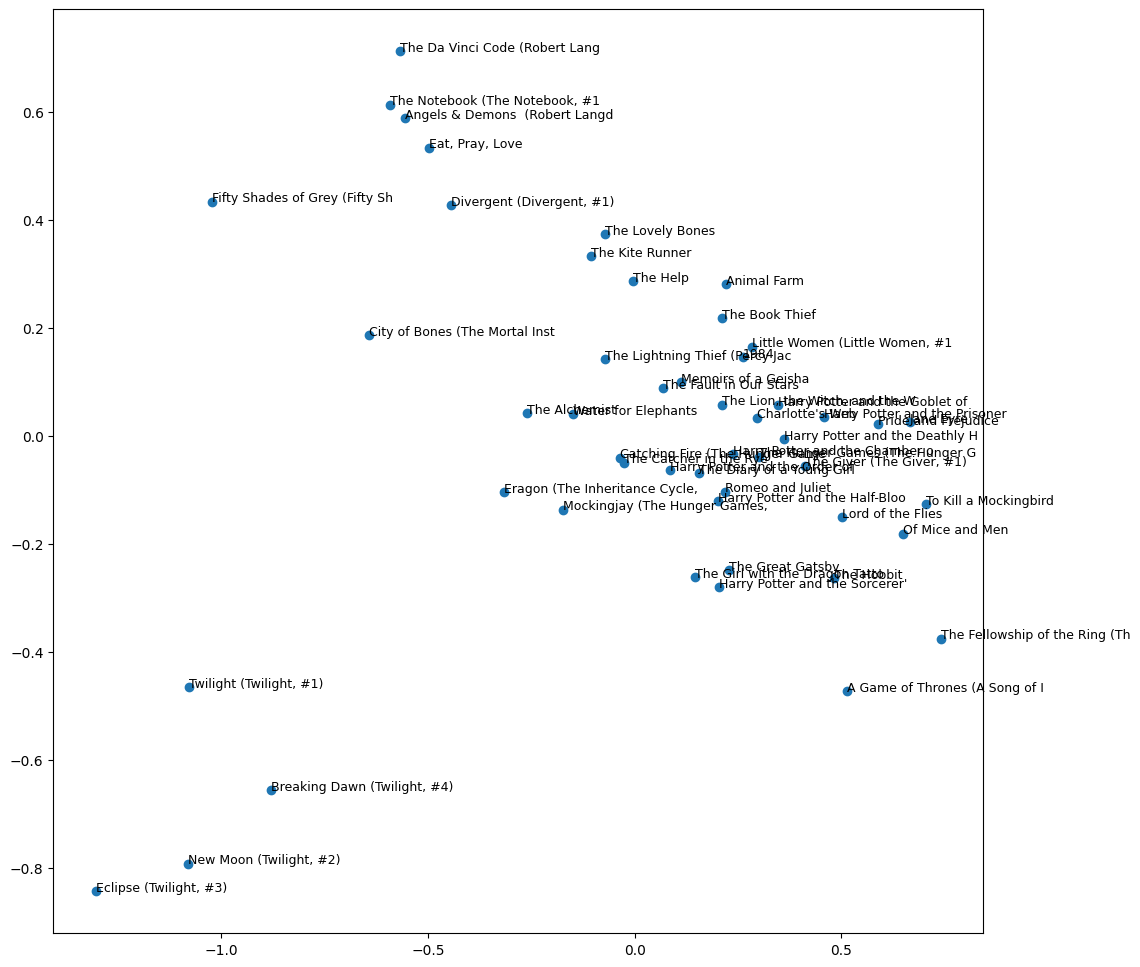

In [75]:
book_w = learn.model.book_factors.weight[top_idxs].cpu().detach()
fac0, fac1, fac2 = book_w.pca(3).t()

plt.figure(figsize=(12, 12))
plt.scatter(fac0, fac2)
for title, x, y in zip(top_books, fac0, fac2):
    plt.text(x, y, title[:30], fontsize=9)
plt.show()
# scatter and text BOTH use fac0 (x) and fac2 (y), so each label sits on its dot

# Use the model

In [89]:
pop_titles = [t for t in popular.title if t in vocab.o2i][:1000]
pop_idxs = tensor([vocab.o2i[t] for t in pop_titles])
# The 1,000 most popular books on Goodreads → better-learned taste cards

def similar_books(title, n=5):
    w = learn.model.book_factors.weight[pop_idxs].cpu().detach()
    target = learn.model.book_factors.weight[vocab.o2i[title]].cpu().detach()
    sims = nn.CosineSimilarity(dim=1)(w, target[None])
    # Same cosine similarity as before, but only against the 1,000 popular books
    top = sims.argsort(descending=True)
    return [pop_titles[i] for i in top if pop_titles[i] != title][:n]
    # Skip the book itself, return the top n

similar_books('Twilight (Twilight, #1)')


['New Moon (Twilight, #2)',
 'Eclipse (Twilight, #3)',
 'The Alchemist',
 "Hatchet (Brian's Saga, #1)",
 'City of Bones (The Mortal Instruments, #1)']

## Top picks for one user

In [84]:
vocab_u = learn.dls.classes['user_id']
uid = 1

u_idx = vocab_u.o2i[uid]
read = set(sample[sample.user_id == uid].title)

all_books = tensor(range(len(vocab)))
pairs = torch.stack([tensor([u_idx] * len(vocab)), all_books], dim=1).to(learn.dls.device)
# Build (this user, every book) pairs: shape [9965, 2], the same format as training

with torch.no_grad():
    preds = learn.model(pairs).squeeze().cpu()
# Predict this user's rating for EVERY book in one go

recs = [(vocab[i], round(preds[i].item(), 2)) for i in preds.argsort(descending=True)
        if vocab[i] not in read][:10]
recs
# The 10 highest predicted ratings among books they haven't read yet

[('Humans of New York', 4.26),
 ('Preach My Gospel: A Guide To Missionary Service', 4.24),
 ('Humans of New York: Stories', 4.2),
 ('Harry Potter Collection (Harry Potter, #1-6)', 4.19),
 ('Rita Hayworth and Shawshank Redemption: A Story from Different Seasons',
  4.17),
 ('Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)', 4.14),
 ('Locke & Key, Vol. 6: Alpha & Omega', 4.14),
 ('The Day the Crayons Quit', 4.12),
 ('Harry Potter and the Order of the Phoenix (Harry Potter, #5, Part 1)',
  4.11),
 ('The Absolute Sandman, Volume One', 4.1)]